# WaveWatch III Hawaiʻi, best series: virtual Icechunk smoke test (local)

A smoke test for the virtual Icechunk store planned in
[issue #13](https://github.com/ocean-icechunks/pacioos/issues/13): the PacIOOS WaveWatch III
(WW3) regional wave model for the main Hawaiian Islands (`ww3_hawaii`), served as PacIOOS's
THREDDS serves it, as one **"best" time series** across the daily runs. The data are read from
the unchanged NetCDF copies on Source Cooperative:

`https://data.source.coop/ocean-icechunks/pacioos/ww3_hawaii/netcdf/<year>/ww3hawaii_<YYYYMMDD>.nc`

The store holds only Zarr metadata and byte-range references, and every read goes back to those
files. The planned destination is `ocean-icechunks/pacioos/ww3_hawaii/icechunk/`. **This notebook
does not write there.** It writes only to a temporary local directory, which it deletes at the end.

## What this notebook checks, one small store per case

| Case | Runs | What it shows |
|---|---|---|
| A. The 2020 suspect week | 2020-04-24 … 05-06 | the tie at 2020-04-26T21Z goes to the later name (`20200427`), as on ERDDAP; the 8 suspect files are flagged |
| B. Short runs and a hole | 2013-07-31 … 08-17 | the 73- and 106-step runs of 2013-08; an uncovered stretch reads as NaN on a regular axis |
| C. A long hole and the land change | 2015-11-28, 2015-12-30 | 587 uncovered hours; the fill area grows from 1,051 to 1,062 cells |
| D. 2026 cold starts | 2026-10-15 … 10-28 | cold starts are flagged; their first step is all zero, as ERDDAP serves it |
| E. Wrong year folder and the year change | 2020-12-28 … 2021-01-02 | two files in the `2021` folder are found from the listing |
| F. The 2024 hand-fixed files | 2024-02-28 … 03-04 | the second header layout (a longer header) |

In every case the store is reopened read-only, as a reader would, and sampled planes are
compared with netCDF-C reads of the files.

## Running it

No credentials; about 3 minutes. Install with `pip install -r requirements.txt` in this folder
(Python 3.12 or newer). The build code is in `ww3_store.py`, shared with the production build.
This notebook's source is `make_smoke_notebook.py`.

**Decisions** (Eli Holmes, 2026-11-14, issue #13): the THREDDS best rule, ties to the later
file name; a regular hourly axis, with uncovered times as NaN steps; `(time, lat, lon)` arrays
with `z = 0` as a scalar coordinate; `lon` 0–360 as in the files; a `best_step_flag`
coordinate for cold starts and suspect time labels; metadata from ERDDAP, said so in
`metadata_source`; yearly manifest splits.

In [1]:
import sys
sys.path.insert(0, '..')

import shutil
import tempfile
import time
import urllib.request
from pathlib import Path

import icechunk
import kerchunk
import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import pandas as pd
import virtualizarr
import xarray as xr
import zarr

import pacioos_virtual as pv
import ww3_store as ws

icechunk.set_logs_filter('error')
for name, mod in [('icechunk', icechunk), ('virtualizarr', virtualizarr), ('xarray', xr),
                  ('zarr', zarr), ('kerchunk', kerchunk), ('netCDF4', netCDF4), ('numpy', np)]:
    print(f'{name:13s}{mod.__version__}')
print(f'{"python":13s}{sys.version.split()[0]}')

icechunk     2.3.1
virtualizarr 2.8.0
xarray       2026.9.0
zarr         3.4.2
kerchunk     0.2.10
netCDF4      1.7.5.1.post1
numpy        2.5.4
python       3.12.12


## 1. The runs, from the listing

In [2]:
KEYS = ws.list_runs()
BY_NAME = {ws.name_date(k): k for k in KEYS}
print(f'{len(KEYS)} runs on Source Cooperative: {KEYS[0]} .. {KEYS[-1]}')
print('files not in the folder of their name year:',
      [k for k in KEYS if k.split('/')[2] != f'{ws.name_date(k):%Y}'])

WORK = Path(tempfile.mkdtemp(prefix='pacioos-ww3-smoke-'))
zarr.config.set({'async.concurrency': 128})
print('work dir:', WORK)

req = urllib.request.Request(ws.URL_PREFIX + KEYS[0], headers={'Range': 'bytes=0-3'})
with urllib.request.urlopen(req) as r:
    assert r.status == 206 and r.read() == b'CDF\x01'
print('byte ranges: 206, NetCDF-3 classic')

5232 runs on Source Cooperative: ww3_hawaii/netcdf/2011/ww3hawaii_20110621.nc .. ww3_hawaii/netcdf/2026/ww3hawaii_20261111.nc
files not in the folder of their name year: ['ww3_hawaii/netcdf/2021/ww3hawaii_20201230.nc', 'ww3_hawaii/netcdf/2021/ww3hawaii_20201231.nc']
work dir: /tmp/pacioos-ww3-smoke-v0011qe2


byte ranges: 206, NetCDF-3 classic


## 2. One file, inspected

`ws.scan` is `pv.scan_nc3` (kerchunk's NetCDF-3 header parser: per variable, the offset of every
record slab) plus one read of the first `Thgt` plane, which says whether the run is a cold start,
and a comparison of the first time with the name date.

In [3]:
s0 = ws.scan(BY_NAME[pd.Timestamp('2026-10-26')])
rows = [{'variable': n, 'dims': v['dims'], 'dtype': v['dtype'], 'slabs': len(v['offsets']),
         'slab bytes': int(v['nbytes'][0]), 'attributes': v['attrs']} for n, v in s0['vars'].items()]
print(pd.DataFrame(rows).to_string(index=False))
print('\ntime:', s0['time'][0], '...', s0['time'][-1], f'({len(s0["time"])} hourly steps)')
print('z =', s0['coords']['z'], '| lon', float(s0['coords']['lon'][0]), '..', float(s0['coords']['lon'][-1]))
print('cold start:', s0['cold_start'], '| suspect time label:', s0['suspect_time'])
for n in ws.SCIENCE:
    v = s0['vars'][n]
    assert v['dims'] == ('time', 'z', 'lat', 'lon') and (v['nbytes'] == ws.PLANE).all()
    assert len(set(np.diff(v['offsets'].astype('int64')))) == 1     # one record apart

variable                dims dtype  slabs  slab bytes                                                                                                                                                                                                  attributes
     lon              (lon,)   >f4      1         564                                                                                         {'long_name': 'longitude', 'standard_name': 'longitude', 'short_name': 'lon', 'axis': 'x', 'units': 'degrees_east'}
     lat              (lat,)   >f4      1         404                                                                                          {'long_name': 'latitude', 'standard_name': 'latitude', 'short_name': 'lat', 'axis': 'y', 'units': 'degrees_north'}
       z                (z,)   >f4      1           4                                                                                {'long_name': 'depth below mean sea level', 'standard_name': 'depth', 'short_name': 'depth', 

The files' own metadata: good variable attributes, but the only global attribute is a title.

In [4]:
import fsspec
with netCDF4.Dataset(ws.URL_PREFIX + s0['key'] + '#mode=bytes') as nc:
    print({a: nc.getncattr(a) for a in nc.ncattrs()})

{'title': 'WaveWatch-III results from ORE level2 model.  Results provided by Ning Li, K.-F. Cheung, PI.....................................................................................................................................................'}


## 3. Metadata from PacIOOS's ERDDAP

ERDDAP's `ww3_hawaii` record has a full set of global attributes (title, summary, license,
creator, keywords …) and CF attributes on every variable, including the corrected `Tdir`
`standard_name` (ERDDAP, 2025-05-08). The store takes them from the saved copy,
`erddap_metadata.json`, and says so in its `metadata_source` attribute. The fill value stays
the files' `-999`: a virtual store serves the files' bytes (ERDDAP shows NaN because it
converts them). ERDDAP calls the vertical coordinate `depth`; the store keeps the files' `z`.

In [5]:
ERDDAP_ATTRS, FETCHED = ws.load_metadata()
print('saved ERDDAP metadata, fetched', FETCHED)
diffs = ws.compare_with_live_erddap()
if diffs is not None:
    print('live ERDDAP:', 'no differences' if diffs.empty else '\n' + diffs.to_string(index=False))
VAR_ATTRS = ws.variable_attrs(ERDDAP_ATTRS)

changes = []
for name in ws.SCIENCE + ['lat', 'lon', 'z']:
    file_attrs = s0['vars'][name]['attrs']
    for k in sorted(set(file_attrs) | set(VAR_ATTRS[name])):
        old, new = file_attrs.get(k, '(none)'), VAR_ATTRS[name].get(k, '(dropped)')
        if str(old) != str(new):
            changes.append({'variable': name, 'attribute': k, 'file': old, 'store': new})
print()
print(pd.DataFrame(changes).to_string(index=False))

saved ERDDAP metadata, fetched 2026-11-14T05:13:25Z


live ERDDAP: no differences

variable     attribute                            file                                                                store
    Tper standard_name         sea_surface_wave_period         sea_surface_wave_period_at_variance_spectral_density_maximum
    Tper         units                         seconds                                                               second
    Tdir standard_name sea_surface_wave_from_direction sea_surface_wave_from_direction_at_variance_spectral_density_maximum
     lat          axis                               y                                                                    Y
     lat     long_name                        latitude                                                             Latitude
     lon          axis                               x                                                                    X
     lon     long_name                       longitude                                                 

## 4. Build, write and reopen: the helpers

`ws.build_dataset` orders runs by start time and then by file name, applies the best rule on a
regular hourly axis (`pv.best_assignment`), and writes one reference per step: one 57 KB
`(lat, lon)` plane per variable, the files' own unit. Each case gets its own local repository,
reopened with a new `Repository.open`, as a reader of the published store would.

In [6]:
SCANS = {}


def scans_for(days):
    out = []
    for d in pd.to_datetime(days):
        if d not in BY_NAME:
            continue
        if d not in SCANS:
            SCANS[d] = ws.scan(BY_NAME[d])
        out.append(SCANS[d])
    return out


def build_case(name, days):
    scans = scans_for(days)
    ds = ws.build_dataset(scans, VAR_ATTRS, ERDDAP_ATTRS, FETCHED)
    path = WORK / name
    repo = icechunk.Repository.create(icechunk.local_filesystem_storage(str(path)),
                                      config=ws.repository_config(),
                                      authorize_virtual_chunk_access=pv.reader_authorization())
    repo.save_config()
    session = repo.writable_session('main')
    ds.vz.to_icechunk(session.store)
    session.commit(name)
    st = icechunk.local_filesystem_storage(str(path))
    return ws.open_store(st), ws.open_store(st, mask_and_scale=False), scans


def check_values(ds, raw, picks, names=('Thgt', 'Tdir', 'wper')):
    """Sampled planes against netCDF-C reads of the file each step came from."""
    frt = pd.DatetimeIndex(ds.forecast_reference_time.values)
    n = 0
    for i in picks:
        if pd.isna(frt[i]):
            assert np.isnan(ds.Thgt.isel(time=i).values).all()
            continue
        lead = int(ds.forecast_period.values[i])
        # the run is identified by its start; among equal starts, the later name
        cand = [s for s in SCANS.values() if s['time'][0] == frt[i]]
        s = ws.order_runs(cand)[-1]
        with netCDF4.Dataset(ws.URL_PREFIX + s['key'] + '#mode=bytes') as nc:
            for name in names:
                v = nc[name]
                v.set_auto_maskandscale(False)
                assert np.array_equal(raw[name].isel(time=i).values, v[lead, 0]), (str(ds.time.values[i]), name)
                n += 1
    return n


def regular(ds):
    t = pd.DatetimeIndex(ds.time.values)
    return bool((np.diff(t) == np.timedelta64(1, 'h')).all())

## 5. Case A: the 2020 suspect week, and a tie

`ww3hawaii_20200426.nc` and `…0427.nc` both start at 2020-04-26T21Z. THREDDS gives the steps to
the later file name: on ERDDAP, 2020-04-27T06Z holds `0427`'s value (1.62 against 1.72 from `0426`,
audit P3). The eight files `0427` … `0504` start at 21Z the day before their name date; they are
served as they are and flagged (`best_step_flag` bit 2).

In [7]:
A, A_raw, A_scans = build_case('A', pd.date_range('2020-04-24', '2020-05-06'))
frt = pd.DatetimeIndex(A.forecast_reference_time.values)
assert regular(A) and not frt.isna().any()
suspect = [s['key'].rsplit('/', 1)[-1] for s in A_scans if s['suspect_time']]
print('suspect files:', suspect)
assert suspect == [f'ww3hawaii_202004{d}.nc' for d in (27, 28, 29, 30)] + [f'ww3hawaii_202005{d:02d}.nc' for d in (1, 2, 3, 4)]

# the tie: the step at 2020-04-27T06Z comes from 0427, not 0426 (same start)
i = int(np.where(A.time.values == np.datetime64('2020-04-27T06:00'))[0][0])
with netCDF4.Dataset(ws.URL_PREFIX + BY_NAME[pd.Timestamp('2020-04-27')] + '#mode=bytes') as nc:
    lead = int(A.forecast_period.values[i])
    assert np.array_equal(A_raw.Thgt.isel(time=i).values, nc['Thgt'][lead, 0])
print(f'2020-04-27T06Z: from the run starting {frt[i]} at +{lead} h, the file ww3hawaii_20200427.nc (the later name)')

flag = A.best_step_flag.values
t = pd.DatetimeIndex(A.time.values)
flagged = t[(flag & ws.FLAG_SUSPECT_TIME) > 0]
print(f'{len(flagged)} steps flagged suspect_time_label: {flagged[0]} .. {flagged[-1]}')
n = check_values(A, A_raw, sorted({0, len(t) - 1, i} | set(np.where(np.diff(frt.asi8) != 0)[0] + 1)))
print(f'{n} planes identical to netCDF-C (every run change, first and last step)')

suspect files: ['ww3hawaii_20200427.nc', 'ww3hawaii_20200428.nc', 'ww3hawaii_20200429.nc', 'ww3hawaii_20200430.nc', 'ww3hawaii_20200501.nc', 'ww3hawaii_20200502.nc', 'ww3hawaii_20200503.nc', 'ww3hawaii_20200504.nc']


2020-04-27T06Z: from the run starting 2020-04-26 21:00:00 at +9 h, the file ww3hawaii_20200427.nc (the later name)
216 steps flagged suspect_time_label: 2020-04-26 21:00:00 .. 2020-05-05 20:00:00


42 planes identical to netCDF-C (every run change, first and last step)


## 6. Case B: short runs and a hole (2013-08)

Four runs of 2013-08-02 … 05 have 73 steps and 08-16 has 106. No run covers 2013-08-08T22Z …
08-14T08Z: those 131 steps stay on the regular axis with no reference.

In [8]:
B, B_raw, B_scans = build_case('B', pd.date_range('2013-07-31', '2013-08-17'))
print('run lengths:', sorted({len(s['time']) for s in B_scans}))
frt = pd.DatetimeIndex(B.forecast_reference_time.values)
t = pd.DatetimeIndex(B.time.values)
gap = t[frt.isna()]
print(f'{len(gap)} uncovered steps on a regular axis:', regular(B),
      '| stretches:', [(str(g[0]), str(g[-1]), len(g)) for g in np.split(gap, np.where(np.diff(gap) != np.timedelta64(1, 'h'))[0] + 1)])
assert regular(B) and pd.Timestamp('2013-08-08T22') in gap and pd.Timestamp('2013-08-14T08') in gap
assert np.isnan(B.Thgt.sel(time='2013-08-10T00').values).all()
assert np.isnan(B.forecast_period.values[frt.isna()]).all()
# the covered steps are exactly ERDDAP's times for this span
erd = pd.to_datetime(open('../../audit/out/erddap_time_ww3_hawaii.csv').read().split()[2:], utc=True).tz_localize(None) \
    if Path('../../audit/out/erddap_time_ww3_hawaii.csv').exists() else None
if erd is not None:
    covered = t[~frt.isna()]
    span = erd[(erd >= covered[0]) & (erd <= covered[-1])]
    assert span.equals(covered), 'the covered steps differ from ERDDAP\'s times'
    print(f'the {len(covered)} covered steps equal ERDDAP\'s times over the span (audit copy of its axis)')
n = check_values(B, B_raw, sorted({0, len(t) - 1} | set(np.where(np.diff(frt.asi8) != 0)[0] + 1)))
print(f'{n} planes identical to netCDF-C')

run lengths: [73, 106, 181]
131 uncovered steps on a regular axis: True | stretches: [('2013-08-08 22:00:00', '2013-08-14 08:00:00', 131)]
the 398 covered steps equal ERDDAP's times over the span (audit copy of its axis)


27 planes identical to netCDF-C


## 7. Case C: the 24-day hole of 2015-12, and the land change

The run of 2015-11-28 ends at 12-06T09Z; the next, 2015-12-30, starts at 21Z. Between them, 587
hours with no reference. The fill (land) area grows from 1,051 to 1,062 cells at the 12-30 run.

In [9]:
C, C_raw, C_scans = build_case('C', ['2015-11-28', '2015-12-30'])
frt = pd.DatetimeIndex(C.forecast_reference_time.values)
print(f'{int(frt.isna().sum())} uncovered steps; axis regular: {regular(C)}')
assert int(frt.isna().sum()) == 587
land_before = int((C_raw.Thgt.isel(time=0).values == ws.FILL).sum())
land_after = int((C_raw.Thgt.isel(time=-1).values == ws.FILL).sum())
print('fill cells, first and last step:', land_before, land_after)
assert (land_before, land_after) == (1051, 1062)
assert int(np.isnan(C.Thgt.isel(time=-1).values).sum()) == 1062

587 uncovered steps; axis regular: True
fill cells, first and last step: 1051 1062


## 8. Case D: the 2026 cold starts

Runs that start from an all-zero wave field. ERDDAP serves them as they are (`Thgt = 0.0` at
2026-10-27T06Z); the store does too, and flags every step they supply (bit 1).

cold starts: ['ww3hawaii_20261018.nc', 'ww3hawaii_20261020.nc', 'ww3hawaii_20261022.nc', 'ww3hawaii_20261027.nc']
325 of 469 steps flagged cold_start_run


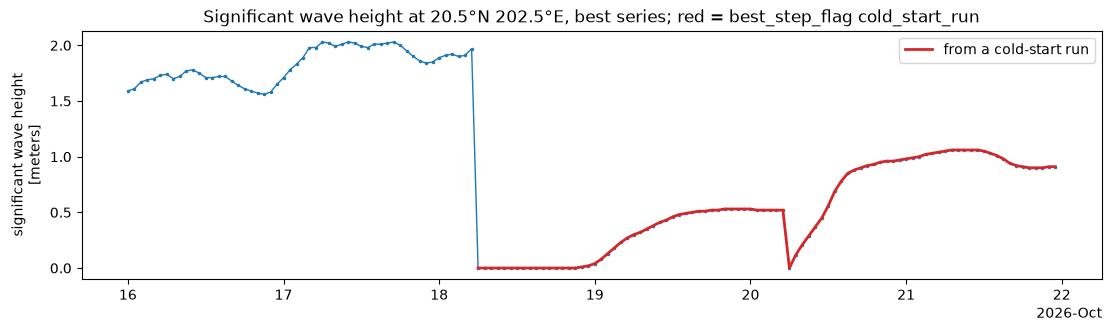

33 planes identical to netCDF-C


In [10]:
D, D_raw, D_scans = build_case('D', pd.date_range('2026-10-15', '2026-10-28'))
cold = [s['key'].rsplit('/', 1)[-1] for s in D_scans if s['cold_start']]
print('cold starts:', cold)
assert cold == ['ww3hawaii_20261018.nc', 'ww3hawaii_20261020.nc', 'ww3hawaii_20261022.nc', 'ww3hawaii_20261027.nc']
first = D.Thgt.sel(time='2026-10-27T06:00')
sea = ~np.isnan(first.values)
assert (first.values[sea] == 0).all() and int(D.best_step_flag.sel(time='2026-10-27T06:00')) == ws.FLAG_COLD_START
t = pd.DatetimeIndex(D.time.values)
flag = D.best_step_flag.values
print(f'{int(((flag & ws.FLAG_COLD_START) > 0).sum())} of {len(t)} steps flagged cold_start_run')

# the spin-up, at a sea point, through the cold start of 10-18 (the previous run, 10-17, for comparison)
pt = dict(lat=20.5, lon=202.5)
series = D.Thgt.sel(time=slice('2026-10-16', '2026-10-21')).sel(pt, method='nearest').load()
fig, ax = plt.subplots(figsize=(11, 3.2), constrained_layout=True)
series.plot(ax=ax, lw=1, marker='.', ms=3)
cs = series.where((series.best_step_flag & ws.FLAG_COLD_START) > 0)
cs.plot(ax=ax, color='C3', lw=2, label='from a cold-start run')
ax.set_title('Significant wave height at 20.5°N 202.5°E, best series; red = best_step_flag cold_start_run')
ax.set_xlabel(''); ax.legend()
plt.show()
n = check_values(D, D_raw, sorted({0, len(t) - 1} | set(np.where(np.diff(pd.DatetimeIndex(D.forecast_reference_time.values).asi8) != 0)[0] + 1)))
print(f'{n} planes identical to netCDF-C')

## 9. Cases E and F: the wrong year folder, and the second header layout

In [11]:
E, E_raw, E_scans = build_case('E', pd.date_range('2020-12-28', '2021-01-02'))
print('files used:', [s['key'] for s in E_scans])
assert sum('/2021/ww3hawaii_2020' in s['key'] for s in E_scans) == 2
t = pd.DatetimeIndex(E.time.values)
frt = pd.DatetimeIndex(E.forecast_reference_time.values)
n = check_values(E, E_raw, sorted({0, len(t) - 1} | set(np.where(np.diff(frt.asi8) != 0)[0] + 1)))
print(f'E: {n} planes identical to netCDF-C, across the year change')

F, F_raw, F_scans = build_case('F', pd.date_range('2024-02-28', '2024-03-04'))
offs = sorted({int(s['vars']['Thgt']['offsets'][0]) for s in F_scans})
print('Thgt first offsets in these files:', offs, '(two header layouts)')
assert len(offs) == 2
t = pd.DatetimeIndex(F.time.values)
frt = pd.DatetimeIndex(F.forecast_reference_time.values)
n = check_values(F, F_raw, sorted({0, len(t) - 1} | set(np.where(np.diff(frt.asi8) != 0)[0] + 1)))
print(f'F: {n} planes identical to netCDF-C, across the header-layout change')

files used: ['ww3_hawaii/netcdf/2020/ww3hawaii_20201228.nc', 'ww3_hawaii/netcdf/2020/ww3hawaii_20201229.nc', 'ww3_hawaii/netcdf/2021/ww3hawaii_20201230.nc', 'ww3_hawaii/netcdf/2021/ww3hawaii_20201231.nc', 'ww3_hawaii/netcdf/2021/ww3hawaii_20210101.nc', 'ww3_hawaii/netcdf/2021/ww3hawaii_20210102.nc']


E: 21 planes identical to netCDF-C, across the year change


Thgt first offsets in these files: [4576, 4760] (two header layouts)


F: 21 planes identical to netCDF-C, across the header-layout change


## 10. Structure, decoding and timings

In [12]:
ds = D
assert dict(ds.sizes) == {'time': ds.sizes['time'], 'lat': 101, 'lon': 141}
assert 'z' in ds.coords and ds.z.ndim == 0 and float(ds.z) == 0.0 and ds.z.attrs['units'] == 'm'
assert set(ds.data_vars) == set(ws.SCIENCE)
for name in ws.SCIENCE:
    assert ds[name].dims == ('time', 'lat', 'lon') and ds[name].encoding['chunks'] == (1, 101, 141)
assert ds.Tdir.attrs['standard_name'] == 'sea_surface_wave_from_direction_at_variance_spectral_density_maximum'
assert ds.attrs['title'] == 'WaveWatch III (WW3) Hawaii Regional Wave Model'
assert 'ERDDAP' in ds.attrs['metadata_source']
assert float(ds.lon.min()) > 180, 'lon is 0-360, as in the files'
print('structure: (time, lat, lon), chunks (1, 101, 141), scalar z = 0 m, lon 0-360, ERDDAP attributes')
print('metadata_source:', ds.attrs['metadata_source'][:120], '...')

timings = {}
t0 = time.perf_counter(); ds.Thgt.isel(time=100).load(); timings['one map'] = time.perf_counter() - t0
t0 = time.perf_counter(); ds.Thgt.sel(lat=20.5, lon=202.5, method='nearest').load()
timings[f'point series, {ds.sizes["time"]} steps'] = time.perf_counter() - t0
for k, s in timings.items():
    print(f'  {k:32s} {s:6.2f} s   (async.concurrency = {zarr.config.get("async.concurrency")})')

structure: (time, lat, lon), chunks (1, 101, 141), scalar z = 0 m, lon 0-360, ERDDAP attributes
metadata_source: Variable and global attributes from PacIOOS ERDDAP dataset ww3_hawaii (https://pae-paha.pacioos.hawaii.edu/erddap/info/w ...


  one map                            0.07 s   (async.concurrency = 128)
  point series, 469 steps            0.79 s   (async.concurrency = 128)


## 11. Still unknown before the production build

- **Every file's header.** 70-odd files were scanned here; the production build scans all 5,232
  and checks their structure, and that the flags find exactly the audit's 81 cold starts and 8
  suspect files.
- **The full axis against ERDDAP.** About 135,100 hourly steps, of which the covered ones must
  equal ERDDAP's `ww3_hawaii` times over the copied span.
- **Full-length timings**, and the viewer in a browser.

## 12. Clean up

In [13]:
assert WORK.name.startswith('pacioos-ww3-smoke-') and WORK.parent == Path(tempfile.gettempdir())
shutil.rmtree(WORK)
print('removed', WORK)

removed /tmp/pacioos-ww3-smoke-v0011qe2
